# Reinforcement Learning Visualised


This **enhanced Google Colab notebook** includes:
✅ Q-learning logic and Gridworld implementation  
✅ Visual animation of agent learning  
✅ **Q-table evolution visualization during training**  
✅ **Reward per episode plot to observe learning convergence**  

Run cells sequentially to build intuitive understanding.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import random


## Setting up Gridworld and Q-learning

In [ ]:

grid_size = 4
goal_state = (3, 3)

Q_table = np.zeros((grid_size, grid_size, 4))
rewards_per_episode = []

def get_next_state(state, action):
    i, j = state
    if action == 0 and i > 0: i -= 1
    elif action == 1 and i < grid_size - 1: i += 1
    elif action == 2 and j > 0: j -= 1
    elif action == 3 and j < grid_size - 1: j += 1
    return (i, j)

def get_reward(state):
    return 10 if state == goal_state else -1

snapshots = []

for episode in range(500):
    state = (0, 0)
    total_reward = 0
    for _ in range(50):
        action = random.choice(range(4)) if random.uniform(0, 1) < 0.2 else np.argmax(Q_table[state[0], state[1]])
        next_state = get_next_state(state, action)
        reward = get_reward(next_state)
        total_reward += reward
        old_value = Q_table[state[0], state[1], action]
        next_max = np.max(Q_table[next_state[0], next_state[1]])
        Q_table[state[0], state[1], action] = old_value + 0.1 * (reward + 0.95 * next_max - old_value)
        state = next_state
        if state == goal_state:
            break
    rewards_per_episode.append(total_reward)
    if episode % 50 == 0:
        snapshots.append(np.max(Q_table, axis=2).copy())

print("✅ Training complete. Q-table learned.")


✅ Training complete. Q-table learned.


## Visualizing Q-table Evolution

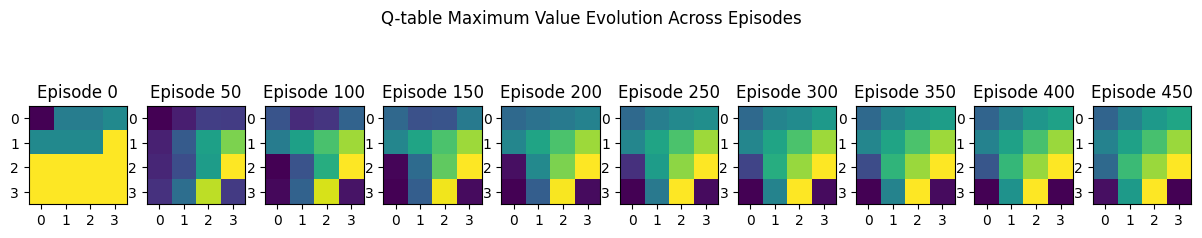

In [ ]:

import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, len(snapshots), figsize=(15, 3))

for idx, snapshot in enumerate(snapshots):
    axs[idx].imshow(snapshot, cmap='viridis')
    axs[idx].set_title(f'Episode {idx * 50}')
    axs[idx].set_xticks(range(grid_size))
    axs[idx].set_yticks(range(grid_size))

plt.suptitle('Q-table Maximum Value Evolution Across Episodes')
plt.show()


## Plotting Rewards per Episode (Convergence Tracking)

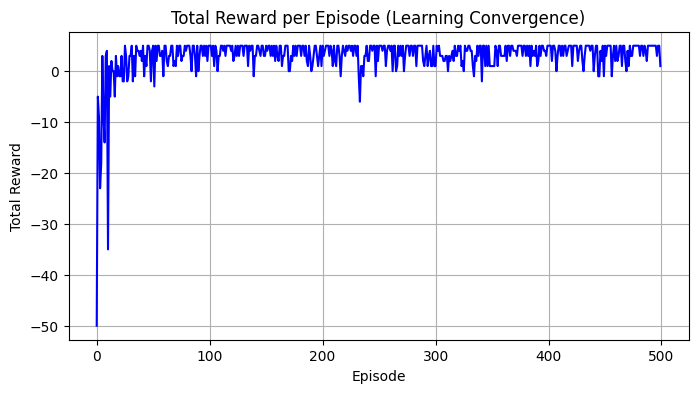

In [ ]:

plt.figure(figsize=(8, 4))
plt.plot(rewards_per_episode, color='blue')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('Total Reward per Episode (Learning Convergence)')
plt.grid(True)
plt.show()



## ✅ Reflection

You now see:
- **How the Q-table values evolve over episodes** during learning.
- **Convergence of rewards** indicating the agent's learning progress.

Use these insights to tune hyperparameters or compare different RL algorithms in future experiments.


In [ ]:

import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# ==================================================
# 1. SETUP
# ==================================================

grid_size = 4
goal_state = (3, 3)

Q_table = np.zeros((grid_size, grid_size, 4))
rewards_per_episode = []
snapshots = []
episode_paths = {}

# Set seed for reproducibility
random.seed(42)
np.random.seed(42)

def get_next_state(state, action):
    i, j = state
    if action == 0 and i > 0: i -= 1
    elif action == 1 and i < grid_size - 1: i += 1
    elif action == 2 and j > 0: j -= 1
    elif action == 3 and j < grid_size - 1: j += 1
    return (i, j)

def get_reward(state):
    return 10 if state == goal_state else -1


# ==================================================
# 2. TRAIN ROBOT AND RECORD EPISODES 1 AND 500
# ==================================================

for episode in range(500):
    state = (0, 0)
    total_reward = 0
    path = [state]

    for _ in range(50):
        # 20% exploration, 80% exploitation
        action = (
            random.choice(range(4))
            if random.uniform(0, 1) < 0.2
            else int(np.argmax(Q_table[state[0], state[1]]))
        )

        next_state = get_next_state(state, action)
        reward = get_reward(next_state)
        total_reward += reward

        old_value = Q_table[state[0], state[1], action]
        next_max = np.max(Q_table[next_state[0], next_state[1]])

        Q_table[state[0], state[1], action] = (
            old_value
            + 0.1 * (reward + 0.95 * next_max - old_value)
        )

        state = next_state
        path.append(state)

        if state == goal_state:
            break

    rewards_per_episode.append(total_reward)

    # Record the exact movements
    if episode in (0, 499):
        episode_paths[episode + 1] = path.copy()

    if episode % 50 == 0:
        snapshots.append(np.max(Q_table, axis=2).copy())

print("✅ Training complete. Q-table learned.")

# ==================================================
# 3. ANIMATE EPISODE 1 VS EPISODE 500
# ==================================================

path_first = episode_paths[1]
path_last = episode_paths[500]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

colors = ["#ef4444", "#16a34a"]
paths = [path_first, path_last]
titles = ["EPISODE 1 — BEGINNER", "EPISODE 500 — TRAINED"]

robots = []
trails = []
status_labels = []

for ax, color, title in zip(axes, colors, titles):
    ax.set_xlim(-0.5, grid_size - 0.5)
    ax.set_ylim(grid_size - 0.5, -0.5)
    ax.set_xticks(range(grid_size))
    ax.set_yticks(range(grid_size))
    ax.grid(True, color="#cbd5e1", linewidth=1.5)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=13, fontweight="bold", color=color)

    # Highlight goal
    ax.add_patch(
        plt.Rectangle(
            (2.5, 2.5), 1, 1,
            facecolor="#bbf7d0", alpha=0.8, zorder=0
        )
    )
    ax.text(3, 3, "GOAL", ha="center", va="center",
            fontsize=9, color="#166534", fontweight="bold")

    # Mark starting point
    ax.text(0, 0.35, "START", ha="center",
            fontsize=8, color="#64748b")

    trail, = ax.plot([], [], "-", color=color,
                     linewidth=2.5, alpha=0.6, zorder=2)

    robot, = ax.plot([], [], "o", color=color,
                     markersize=19, markeredgecolor="white",
                     markeredgewidth=2, zorder=3)

    status = ax.text(
        0.5, -0.13, "", transform=ax.transAxes,
        ha="center", fontsize=11
    )

    trails.append(trail)
    robots.append(robot)
    status_labels.append(status)

max_frames = max(len(path_first), len(path_last))

def animate(frame):
    for idx, path in enumerate(paths):
        current = min(frame, len(path) - 1)
        visited = path[:current + 1]

        # Columns are X, rows are Y
        xs = [position[1] for position in visited]
        ys = [position[0] for position in visited]

        trails[idx].set_data(xs, ys)
        robots[idx].set_data([xs[-1]], [ys[-1]])

        moves = len(path) - 1
        reached = path[-1] == goal_state

        if frame >= moves:
            outcome = "GOAL REACHED!" if reached else "TIME LIMIT!"
        else:
            outcome = "Moving..."

        status_labels[idx].set_text(
            f"Move: {current}/{moves} | {outcome}"
        )

    return robots + trails + status_labels

animation = FuncAnimation(
    fig,
    animate,
    frames=max_frames,
    interval=350,  # milliseconds per move
    repeat=False,
    blit=False
)

plt.close(fig)
display(HTML(animation.to_jshtml()))

# ==================================================
# 4. PRINT RESULTS
# ==================================================

print("\nRESULTS")
print("-" * 45)

for ep in (1, 500):
    path = episode_paths[ep]
    print(
        f"Episode {ep}: "
        f"{len(path) - 1} moves | "
        f"Reward = {rewards_per_episode[ep - 1]} | "
        f"Goal reached = {path[-1] == goal_state}"
    )

print("\nShortest possible path: 6 moves")


✅ Training complete. Q-table learned.



RESULTS
---------------------------------------------
Episode 1: 50 moves | Reward = -50 | Goal reached = False
Episode 500: 8 moves | Reward = 3 | Goal reached = True

Shortest possible path: 6 moves


In [ ]:

# ==================================================
# EPISODE 500 — EVALUATION MODE (NO RANDOM MOVES)
# ==================================================

# Use the trained Q-table to find the best learned route
state = (0, 0)
evaluation_path = [state]

for _ in range(50):
    action = int(np.argmax(Q_table[state[0], state[1]]))
    state = get_next_state(state, action)
    evaluation_path.append(state)

    if state == goal_state:
        break

# Compare all three scenarios
paths = [
    episode_paths[1],
    episode_paths[500],
    evaluation_path
]

titles = [
    "EPISODE 1 — BEGINNER",
    "EPISODE 500 — TRAINING",
    "AFTER TRAINING — EVALUATION"
]

colors = ["#ef4444", "#f59e0b", "#16a34a"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

robots, trails, status_labels = [], [], []

for ax, color, title in zip(axes, colors, titles):
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(3.5, -0.5)
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.grid(True, color="#cbd5e1", linewidth=1.5)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=11, fontweight="bold", color=color)

    ax.add_patch(
        plt.Rectangle(
            (2.5, 2.5), 1, 1,
            facecolor="#bbf7d0", alpha=0.8
        )
    )
    ax.text(3, 3, "GOAL", ha="center", va="center",
            fontsize=9, fontweight="bold")
    ax.text(0, 0.35, "START", ha="center", fontsize=8)

    trail, = ax.plot([], [], "-", color=color, linewidth=2.5)
    robot, = ax.plot([], [], "o", color=color,
                     markersize=18, markeredgecolor="white",
                     markeredgewidth=2)

    status = ax.text(
        0.5, -0.13, "", transform=ax.transAxes,
        ha="center", fontsize=10
    )

    trails.append(trail)
    robots.append(robot)
    status_labels.append(status)

def animate_three(frame):
    for idx, path in enumerate(paths):
        current = min(frame, len(path) - 1)
        visited = path[:current + 1]

        xs = [position[1] for position in visited]
        ys = [position[0] for position in visited]

        trails[idx].set_data(xs, ys)
        robots[idx].set_data([xs[-1]], [ys[-1]])

        moves = len(path) - 1

        if frame >= moves:
            outcome = (
                "GOAL REACHED!"
                if path[-1] == goal_state
                else "TIME LIMIT!"
            )
        else:
            outcome = "Moving..."

        status_labels[idx].set_text(
            f"Move {current}/{moves} | {outcome}"
        )

    return robots + trails + status_labels

animation = FuncAnimation(
    fig,
    animate_three,
    frames=max(len(path) for path in paths),
    interval=350,
    repeat=False
)

plt.close(fig)
display(HTML(animation.to_jshtml()))

# Results
print("\nCOMPARISON")
print("-" * 55)

for title, path in zip(titles, paths):
    print(
        f"{title}: {len(path)-1} moves | "
        f"Goal reached: {path[-1] == goal_state}"
    )

print("\nOptimal route: 6 moves")



COMPARISON
-------------------------------------------------------
EPISODE 1 — BEGINNER: 50 moves | Goal reached: False
EPISODE 500 — TRAINING: 8 moves | Goal reached: True
AFTER TRAINING — EVALUATION: 6 moves | Goal reached: True

Optimal route: 6 moves
